# Hypothesis Test: Is the Coin Biased Towards Heads?

We follow the 7 review steps for two versions of the same question. Both use the **same alternative** (biased towards heads) but a different **test statistic**:

* Case 1: Test statistic = **number of heads**

* Case 2: Test statistic = **proportion of heads**

## Hypothesis Testing Steps (Review) From Earn's Slides

Click the image to open the slide.

<a href="https://docs.google.com/presentation/d/1G5pjbKXGn9R8eudqHbcN6xKmsKIngIWuaZ2NqqhVEb4/edit?slide=id.hbeeee8dbb9dc8b_1_167#slide=id.hbeeee8dbb9dc8b_1_167">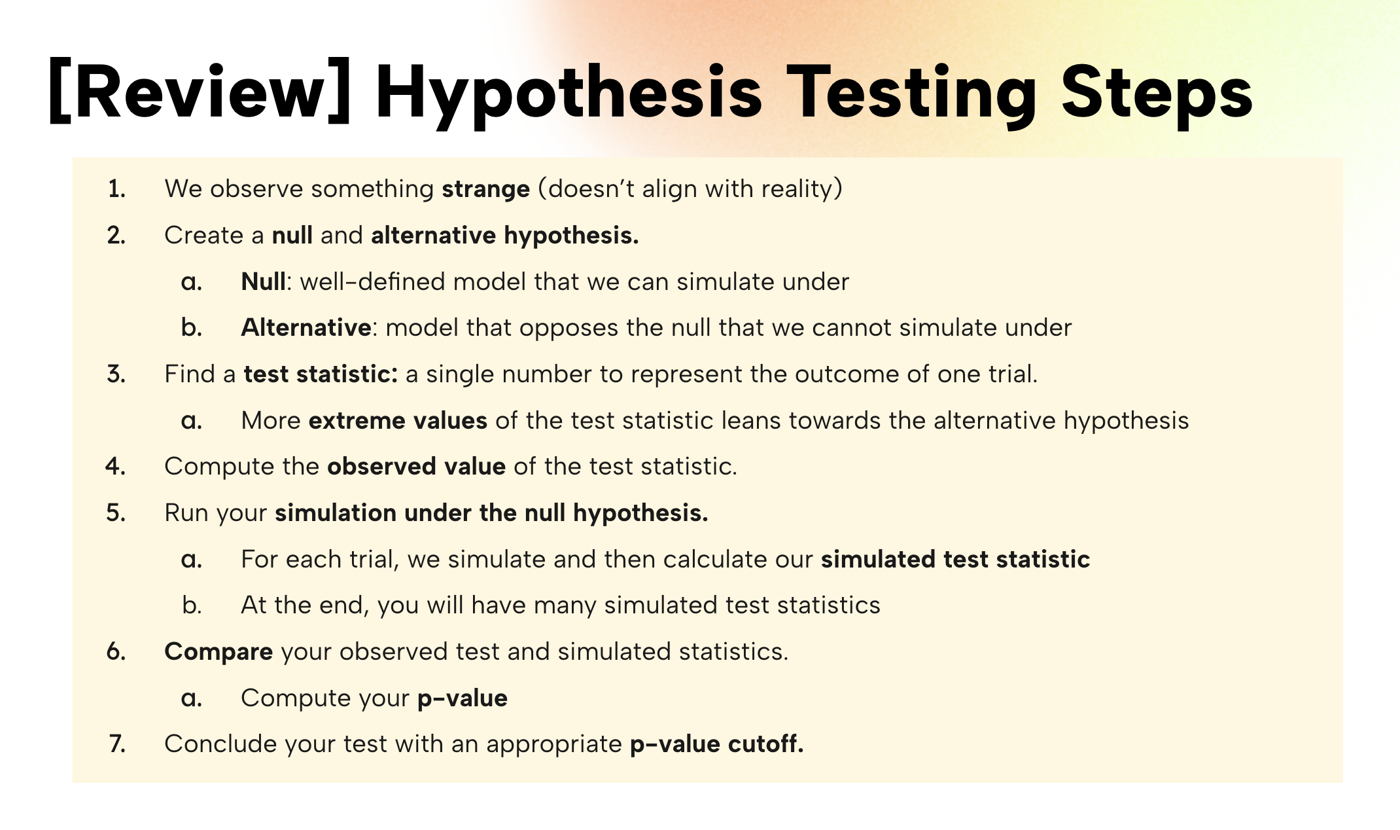</a>

[Open the slide in Google Slides](https://docs.google.com/presentation/d/1G5pjbKXGn9R8eudqHbcN6xKmsKIngIWuaZ2NqqhVEb4/edit?slide=id.hbeeee8dbb9dc8b_1_167#slide=id.hbeeee8dbb9dc8b_1_167)

In [1]:
# The code below are for notebook set-ups. Careful to not delete them!
from datascience import *
import numpy as np
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
%matplotlib inline

np.random.seed(42)

# Feel free to edit the variables below
n_flips = 100        # number of flips in our sample
observed_heads = 62  # number of heads we saw
n_trials = 10000     # number of simulated trials
cutoff = 0.05        # p-value cutoff

# The null model: a fair coin
null_proportions = make_array(0.5, 0.5)   # [Heads, Tails]

## Step 1: We observe something strange
We flipped a coin 100 times and got 62 heads. If the coin were fair we'd expect about 50, so this seems a bit off. Is it just luck, or is the coin biased towards heads?

## Step 2: Null and alternative hypotheses (same for both cases)

- **Null:** The coin is fair. Any observed difference **IS** due to chance.
     * Each flip lands heads with probability 0.5, independently.
     * (Well-defined, so we can simulate under it.)
- **Alternative:** The coin is biased towards heads. Any observed difference is **NOT** due to chance.
     * i.e. P(heads) > 0.5.
     * (Not a single well-defined model, so we can't simulate under it.)*

---
# Case 1: Test statistic = number of heads

## Step 3: Test statistic
The **number of heads** in 100 flips, a single number summarizing one trial.
**Larger** values lean towards the alternative (biased towards heads).

In [2]:
def num_heads(proportions):
    """Test statistic: number of heads, given [prop heads, prop tails]."""
    return np.round(proportions.item(0) * n_flips)

## Step 4: Observed value of the test statistic

In [3]:
observed_stat_1 = observed_heads
observed_stat_1

62

## Step 5: Simulate under the null hypothesis
For each trial, flip a fair coin 100 times (`sample_proportions`) and compute the number of heads.

In [4]:
simulated_stats_1 = make_array()

for i in np.arange(n_trials):
    sim_proportions = sample_proportions(n_flips, null_proportions)
    simulated_stats_1 = np.append(simulated_stats_1, num_heads(sim_proportions))

print("Number of simulated test statistics:", len(simulated_stats_1))
print("First Trial:", simulated_stats_1.item(0))
print("Second Trial:", simulated_stats_1.item(1))
print("Third Trial:", simulated_stats_1.item(2))
print("...")
print(f'{n_trials}th Trial:', simulated_stats_1.item(-1))

Number of simulated test statistics: 10000
First Trial: 46.0
Second Trial: 36.0
Third Trial: 50.0
...
10000th Trial: 55.0


## Step 6: Compare observed vs. simulated statistics and compute the p-value
The alternative is *biased towards heads*, so the p-value is the fraction of simulated statistics **at least as large** as the observed one.

Observed # of heads: 62


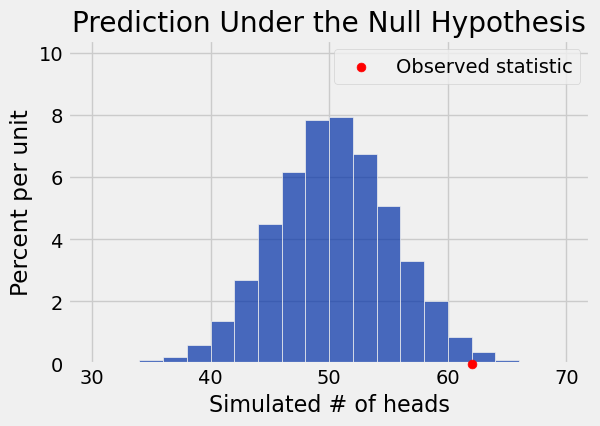

In [5]:
sim_table_1 = Table().with_column('Simulated # of heads', simulated_stats_1)
sim_table_1.hist(bins=np.arange(30, 71, 2))
plots.scatter(observed_stat_1, 0, color='red', s=40, zorder=3, clip_on=False, label='Observed statistic')
plots.title('Prediction Under the Null Hypothesis')
plots.ylim(top=plots.ylim()[1] * 1.25)
plots.legend(loc='upper right')
print("Observed # of heads:", observed_stat_1)

In [6]:
p_value_1 = np.count_nonzero(simulated_stats_1 >= observed_stat_1) / n_trials
p_value_1

0.0109

## Step 7: Conclusion

In [7]:
if p_value_1 < cutoff:
    print("p-value =", p_value_1, "<", cutoff, ": Reject the null. Evidence the coin is biased towards heads.")
else:
    print("p-value =", p_value_1, ">=", cutoff, ": Fail to reject the null. Not enough evidence the coin is biased towards heads.")

p-value = 0.0109 < 0.05 : Reject the null. Evidence the coin is biased towards heads.


---
# Case 2: Test statistic = proportion of heads

## Step 3: Test statistic
The **proportion of heads** (# heads / # flips). **Larger** values lean towards the alternative.

In [8]:
def prop_heads(proportions):
    """Test statistic: proportion of heads, given [prop heads, prop tails]."""
    return proportions.item(0)

## Step 4: Observed value of the test statistic

In [9]:
observed_stat_2 = observed_heads / n_flips
observed_stat_2

0.62

## Step 5: Simulate under the null hypothesis
Same simulation, but each trial's statistic is the proportion of heads.

In [10]:
simulated_stats_2 = make_array()

for i in np.arange(n_trials):
    sim_proportions = sample_proportions(n_flips, null_proportions)
    simulated_stats_2 = np.append(simulated_stats_2, prop_heads(sim_proportions))

print("Number of simulated test statistics:", len(simulated_stats_2))
print("First Trial:", simulated_stats_2.item(0))
print("Second Trial:", simulated_stats_2.item(1))
print("Third Trial:", simulated_stats_2.item(2))
print("...")
print(f'{n_trials}th Trial:', simulated_stats_2.item(-1))

Number of simulated test statistics: 10000
First Trial: 0.55
Second Trial: 0.54
Third Trial: 0.54
...
10000th Trial: 0.4


## Step 6: Compare observed vs. simulated statistics and compute the p-value

Observed proportion of heads: 0.62


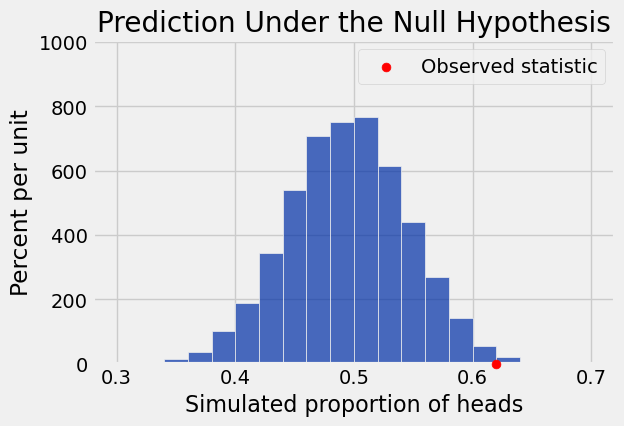

In [11]:
sim_table_2 = Table().with_column('Simulated proportion of heads', simulated_stats_2)
sim_table_2.hist(bins=np.arange(0.3, 0.71, 0.02))
plots.scatter(observed_stat_2, 0, color='red', s=40, zorder=3, clip_on=False, label='Observed statistic')
plots.title('Prediction Under the Null Hypothesis')
plots.ylim(top=plots.ylim()[1] * 1.25)
plots.legend(loc='upper right')
print("Observed proportion of heads:", observed_stat_2)

In [12]:
# small tolerance guards against floating-point equality issues
p_value_2 = np.count_nonzero(simulated_stats_2 >= observed_stat_2 - 1e-9) / n_trials
p_value_2

0.01

## Step 7: Conclusion

In [13]:
if p_value_2 < cutoff:
    print("p-value =", p_value_2, "<", cutoff, ": Reject the null. Evidence the coin is biased towards heads.")
else:
    print("p-value =", p_value_2, ">=", cutoff, ": Fail to reject the null. Not enough evidence the coin is biased towards heads.")

p-value = 0.01 < 0.05 : Reject the null. Evidence the coin is biased towards heads.


---
## Takeaway
Since the number of flips is fixed, *proportion of heads* is just *number of heads ÷ 100*, so both statistics rank every simulated trial the same way. 

The two p-values should be nearly identical (any gap is only simulation randomness).